# Self-Organizing Maps

![](img/banner.png)

Computer Science Dept, Ferdowsi University of Mashhad

## Where this page sits

Section 14.4 of {cite}`hastie2009esl` (pp. 528-533) is the last clustering method of
the chapter, and the book introduces it in one sentence that is also its definition:
a self-organizing map (SOM) is **K-means with the prototypes constrained to lie on a
one- or two-dimensional manifold** in feature space. The constraint is what makes the
result a *map*: the prototypes carry grid coordinates, so every observation can be
placed on a two-dimensional display, and neighbouring cells of the display hold
similar observations.

Kohonen's method is older than the machine-learning vocabulary around it, and it is
still the standard tool for visualising document collections; WEBSOM, the example the
section closes with, is a map of twelve thousand newsgroup articles.

### What you should be able to do at the end

* describe a SOM as a grid of prototypes and write the online update (14.46);
* say what the neighbourhood radius and the learning rate do, and how both are
  scheduled;
* write the batch update (14.48) and show that it becomes K-means when the
  neighbourhood shrinks to one cell;
* judge whether the two-dimensional constraint is acceptable on a given data set by
  comparing reconstruction errors with K-means.

## 1. The model

Fix a grid, say $q_1 \times q_2$ cells, and one prototype $m_j \in \mathbb{R}^p$ per
cell. Each prototype carries an integer coordinate pair $j \in Q_1 \times Q_2$ - its
**position on the map**, not in feature space. The map is a two-dimensional
coordinate system, and the prototypes are points of the feature space assigned to
cells of it.

The book's picture is worth keeping: initialise the prototypes in the plane of the
first two principal components and think of them as **buttons sewn on that plane** in
a regular pattern. Fitting the SOM bends the plane so that the buttons follow the
data. Distances between buttons are measured *on the map*, not in feature space, and
that is the constraint: prototypes that are neighbours on the grid are pulled towards
the same observations, so they stay neighbours in feature space.

## 2. The online algorithm

Observations are processed one at a time. Find the closest prototype to $x_i$ in
$\mathbb{R}^p$, then move **it and its map-neighbours** towards $x_i$:

$$
m_k \leftarrow m_k + \varepsilon\,(x_i - m_k),
\qquad \text{for every } m_k \text{ with } \lVert j - k \rVert \le r .
\qquad \text{(14.46)}
$$

The neighbourhood always contains the winner itself. The general form weights the
step by the map distance,

$$
m_k \leftarrow m_k + h(\lVert j - k \rVert)\,(x_i - m_k),
\qquad \text{(14.47)}
$$

with $h$ decreasing in the map distance - a Gaussian, or the indicator of a disc.

Both schedules in the book go from coarse to fine: the learning rate $\varepsilon$
falls from about $1.0$ to $0$ over a few thousand iterations, and the radius $r$ falls
linearly from an initial $R$ to $1$. Early, large neighbourhoods make the map globally
smooth; late, small ones let it fit local structure. This is the same annealing idea
as in LVQ, and the same warning applies: the method is defined by its schedule, not by
the minimisation of a criterion.

If $r$ is small enough that every neighbourhood is a single cell, the spatial
connection is lost and the algorithm becomes **online K-means**: it converges to one
of the local minima that K-means also finds. That is the sense in which the SOM is a
constrained K-means, and it also tells you how to check the constraint on a given
problem:

$$
\text{reconstruction error} = \sum_i \lVert x_i - m_{j(i)} \rVert^2 .
$$

It is necessarily larger for the SOM than for K-means with the same number of
prototypes. If it is *much* larger, the two-dimensional map is a bad description of
the data.

## 3. A worked example: three clusters on a half sphere

The book's example is 90 points in $\mathbb{R}^3$ near the surface of a half sphere of
radius 1, in three clusters near $(0,1,0)$, $(0,0,1)$ and $(1,0,0)$. The red cluster is
deliberately much tighter than the other two, which is what makes the fitted map fold
back on itself.

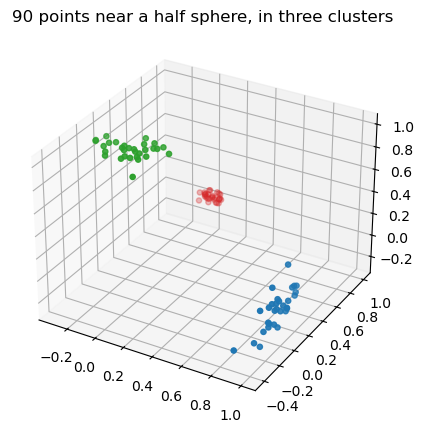

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")

rng = np.random.default_rng(0)


def on_sphere(centre, sd, count):
    P = np.asarray(centre, float) + rng.normal(0.0, sd, size=(count, 3))
    return P / np.linalg.norm(P, axis=1, keepdims=True)


red = on_sphere((0, 1, 0), 0.04, 30)      # the tight cluster
green = on_sphere((0, 0, 1), 0.13, 30)
blue = on_sphere((1, 0, 0), 0.13, 30)
X = np.vstack([red, green, blue])
truth = np.repeat([0, 1, 2], 30)
colours = np.array(["tab:red", "tab:green", "tab:blue"])[truth]

fig = plt.figure(figsize=(5.5, 5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colours, s=14)
ax.set_title("90 points near a half sphere, in three clusters")
plt.show()

The prototypes are initialised on the first two principal components, spread over the
extent of the data - the "buttons sewn on the plane" of the section.

In [2]:
q1 = q2 = 5                       # a 5 x 5 grid: 25 prototypes
mu = X.mean(axis=0)
U, S, Vt = np.linalg.svd(X - mu, full_matrices=False)
scores = (X - mu) @ Vt[:2].T

a1 = np.linspace(scores[:, 0].min(), scores[:, 0].max(), q1)
a2 = np.linspace(scores[:, 1].min(), scores[:, 1].max(), q2)
grid = np.array([[u, v] for u in a1 for v in a2])     # map coordinates, row-major
M0 = mu + grid @ Vt[:2]                               # prototypes in R^3
node = np.array([[i, j] for i in range(q1) for j in range(q2)], float)

print("prototypes:", M0.shape, " map coordinates:", node.shape)

prototypes: (25, 3)  map coordinates: (25, 2)


The training loop is (14.46) verbatim: 40 passes over the 90 observations, 3600
iterations, with $\varepsilon$ and $r$ decreased linearly over those iterations.

In [3]:
def som(X, M, epochs=40, R0=2.0, seed=0, node=node):
    rng = np.random.default_rng(seed)
    M = M.copy()
    errors = []
    total = epochs * len(X)
    t = 0
    for _ in range(epochs):
        for _ in range(len(X)):
            x = X[rng.integers(len(X))]
            j = int(np.argmin(((M - x) ** 2).sum(axis=1)))
            eps = 1.0 - t / total                        # 1.0 -> 0.0
            r = R0 + (1.0 - R0) * t / total              # R0 -> 1
            neighbours = ((node - node[j]) ** 2).sum(axis=1) <= r ** 2
            M[neighbours] += eps * (x - M[neighbours])
            t += 1
        err = (((X[:, None, :] - M[None, :, :]) ** 2).sum(-1).min(axis=1)).sum()
        errors.append(err)
    return M, errors


M, errors = som(X, M0)
print(f"reconstruction error after training: {errors[-1]:.3f}")

from sklearn.cluster import KMeans

km = KMeans(n_clusters=len(M), n_init=10, random_state=0).fit(X)
print(f"K-means with the same 25 prototypes : {km.inertia_:.3f}")

reconstruction error after training: 0.636
K-means with the same 25 prototypes : 0.124


The two numbers are the check the book asks for, and here they are far apart: the
constrained fit costs a factor of about five. That is the price of spreading 25
buttons *evenly* over a surface when the data sit in three tight lumps - the grid
cannot spend all of its cells on the lumps. The book's own data are more diffuse
and its SOM ends within about a quarter of K-means (Figure 14.18); the ratio is a
property of the data, not of the implementation, and reading it is how you decide
whether a two-dimensional map is a fair description of yours.

## 4. Reading the map

The display is the grid. Each cell holds the observations that are closest to its
prototype, drawn at random positions inside the cell - the layout of Figure 14.16. The
left panel is the initial map, the right panel the trained one.

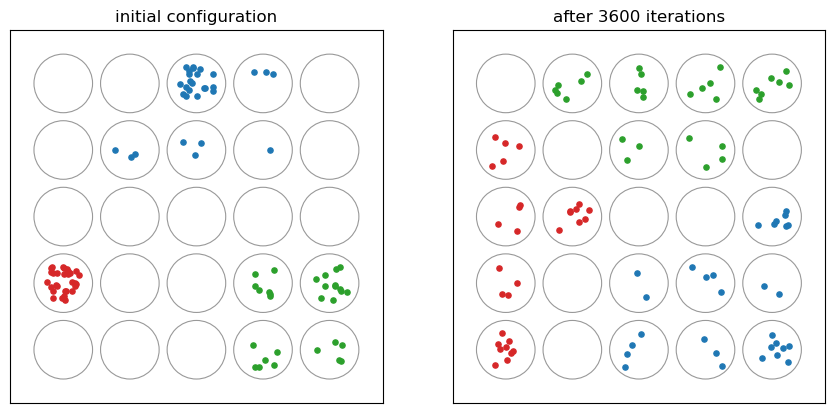

In [4]:
def draw_map(ax, M, X, truth, title, seed):
    r = np.random.default_rng(seed)
    labels = np.argmin(((X[:, None, :] - M[None, :, :]) ** 2).sum(-1), axis=1)
    for i in range(q1):
        for j in range(q2):
            ax.add_patch(plt.Circle((j, q1 - 1 - i), 0.44, fill=False, color="0.6", lw=0.8))
    jitter = r.uniform(-0.26, 0.26, size=(len(X), 2))
    for k, colour in enumerate(["tab:red", "tab:green", "tab:blue"]):
        mask = truth == k
        xs = (labels[mask] % q2) + jitter[mask, 0]
        ys = (q1 - 1 - labels[mask] // q2) + jitter[mask, 1]
        ax.scatter(xs, ys, s=14, color=colour)
    ax.set_xlim(-0.8, q2 - 0.2)
    ax.set_ylim(-0.8, q1 - 0.2)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])


fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
draw_map(axes[0], M0, X, truth, "initial configuration", seed=1)
draw_map(axes[1], M, X, truth, "after 3600 iterations", seed=2)
plt.tight_layout()
plt.show()

The trained map has separated the three colours into neighbouring regions, and it has
done so with a *smooth* boundary: adjacent cells hold similar observations. That is
the property K-means does not have - its labels carry no adjacency, so the same 25
centroids could be permuted at random and mean the same thing.

What the map does **not** show is density or size. The red cluster is much tighter than
the other two, and nothing in the display says so, because the distances used for the
layout are map distances. The book makes the same remark about Figure 14.16.

## 5. The grid in feature space

Drawing the prototypes and the lattice edges in $\mathbb{R}^3$ shows what "bending the
plane" means geometrically. Where the surface has to double back to reach the tight red
cluster, edges lie on top of each other - the fold of Figure 14.17.

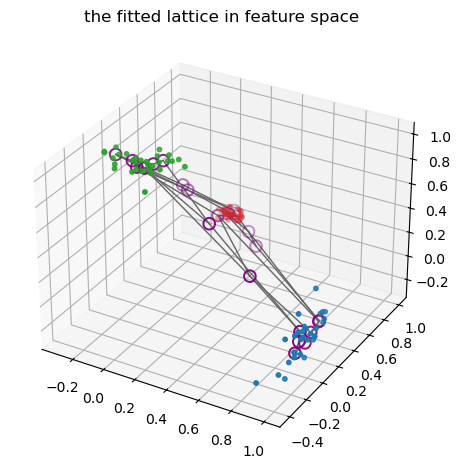

In [5]:
fig = plt.figure(figsize=(6, 5.5))
ax = fig.add_subplot(111, projection="3d")
for i in range(q1):
    for j in range(q2):
        k = i * q2 + j
        if i + 1 < q1:
            ax.plot(*zip(M[k], M[k + q2]), color="0.4", lw=1)
        if j + 1 < q2:
            ax.plot(*zip(M[k], M[k + 1]), color="0.4", lw=1)
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=colours, s=10)
ax.scatter(M[:, 0], M[:, 1], M[:, 2], s=70, facecolors="none",
           edgecolors="purple", linewidths=1.4)
ax.set_title("the fitted lattice in feature space")
plt.show()

## 6. The reconstruction error along the way

The curve that justifies the constraint is the reconstruction error against the
iteration number, with the K-means value as a horizontal line (Figure 14.18).

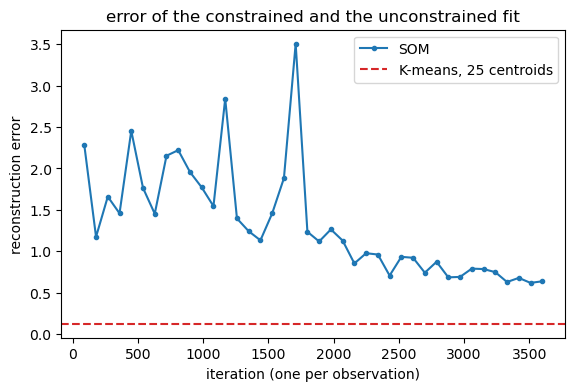

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(np.arange(1, len(errors) + 1) * len(X), errors, "o-", ms=3, label="SOM")
ax.axhline(km.inertia_, color="tab:red", linestyle="--", label="K-means, 25 centroids")
ax.set_xlabel("iteration (one per observation)")
ax.set_ylabel("reconstruction error")
ax.legend()
ax.set_title("error of the constrained and the unconstrained fit")
plt.show()

The error falls quickly while the neighbourhood is wide - the map is being unfolded -
and approaches the K-means level without reaching it. Reading the last part of the
curve is the honest way to answer "is a two-dimensional map appropriate for this
data?", and it is a question about the data, not about the algorithm.

## 7. The batch version, and the relation to K-means

Recomputing the prototype as the weighted mean of the observations that mapped to its
neighbours gives the **batch** SOM:

$$
m_j = \frac{\sum_k w_k x_k}{\sum_k w_k},
\qquad \text{(14.48)}
$$

where the sum runs over observations $x_k$ whose nearest prototype is a map-neighbour
of $j$, and $w_k$ is 1 for a rectangular neighbourhood or falls off with the map
distance. Two special cases are worth knowing:

* a rectangular neighbourhood of radius 0 makes the update "replace each prototype by
  the mean of its own observations", which is K-means;
* a smooth $w$ and a shrinking radius make the batch SOM a discrete version of
  **principal curves**, the topic that follows this section in the book.

Between the online and batch versions the trade-off is the familiar one: online adapts
to a stream and depends on the schedule, batch is deterministic given the assignment,
converges faster, and is what most implementations use by default.

## 8. Where this is used

The closing example of the section is WEBSOM: 12 088 articles from
`comp.ai.neural-nets`, each turned into a sparse vector of relative term frequencies
over a dictionary of tens of thousands of words (or word pairs), optionally reduced by
a randomised SVD, and then mapped onto a grid whose cells are labelled automatically
from their contents. The map is a *browsable* index - zooming into a cell shows the
articles - and that is the application the method was built for: not partitioning for
its own sake, but arranging a large collection so that similar things are near each
other on a page.

## Summary

* A SOM is a grid of prototypes with map coordinates; the update moves the winning
  prototype **and its map-neighbours** towards the observation (14.46).
* The learning rate and the neighbourhood radius both decay; the schedule is part of
  the definition, which is why the method has no criterion to optimise.
* With a single-cell neighbourhood the algorithm is online K-means; the batch form
  (14.48) with radius 0 is K-means exactly.
* The extra error over K-means measures the price of the two-dimensional constraint,
  and reading it is how you decide whether the map is appropriate.
* The output is a display in which neighbouring cells are similar - the property that
  makes the method useful for browsing large collections.

## Exercises

1. Train with $R_0 = 0$ from the start. Compare the error curve and the map with
   K-means labels reshaped onto the grid. What has been lost?
2. Replace the hard neighbourhood of (14.46) by the Gaussian $h(d) = \exp(-d^2/2r^2)$
   of (14.47) and compare the final reconstruction errors.
3. Vary the grid size ($3\times3$, $5\times5$, $8\times8$) at fixed data. How does the
   error approach the K-means line, and what does the map look like at $3\times3$?
4. Use a hexagonal grid (six neighbours per cell instead of four). Does the display
   look better, and is the error different?
5. Run the SOM on 100-dimensional data (e.g. the digits) and measure how much worse
   the constrained solution is. Is a two-dimensional map still defensible?
6. Implement the batch version (14.48) with radius 1 and compare the number of
   iterations needed to reach the same error as the online version.

## Sources

* The definition, (14.46)-(14.48), the half-sphere example with Figures 14.15-14.18,
  and the WEBSOM application: §14.4 of {cite}`hastie2009esl`, pp. 528-533.
* The relation to K-means is the same one used on
  [Clustering-Part2](Clustering-Part2.ipynb); the online-versus-batch trade-off is
  the one discussed in [Perceptron-and-Online-Learning](../learning/Perceptron-and-Online-Learning.md).
* Kohonen's own account of the method, and the WEBSOM papers, are the references
  given in the section.